# 01 · Inventário, manifesto e qualidade dos dados

**Objetivo.** Construir uma visão auditável e reproduzível do conjunto de dados
usado pelo reconhecedor de Libras do projeto Peter, sem alterar nenhum arquivo
original.

**Escopo.** O runtime atual consome 18 templates de treino e avalia 48 sequências
(24 de validação e 24 de teste), todas com 16 frames canônicos e 55 articulações.
Este notebook consolida essas 66 sequências em um manifesto único, mede
integridade estrutural, duplicatas e cobertura das mãos, e produz as tabelas e
figuras usadas nos notebooks seguintes.

**Perguntas orientadoras.**

1. Quais amostras existem, de quais splits, classes e informantes?
2. O manifesto é consistente (frames, fps, articulações, hashes)?
3. Há valores ausentes, duplicatas ou timestamps inválidos?
4. Como a cobertura das mãos varia entre splits e informantes?
5. Que vieses de composição precisam ser lembrados ao interpretar o DTW?

**Fonte.** `src/vision/templates/libras-eqt-dual-*.template.json`,
`src/vision/pipeline/fixtures/libras-eqt-dual-evaluation.json` e o relatório
`libras-eqt-dual-evaluation-results.json`. Todos são lidos em modo somente
leitura; as saídas vão para `eda/outputs`.

**Integridade.** Nenhuma amostra é descartada, imputada ou modificada. As
tabelas registram a origem de cada valor de cobertura e de duração.

In [1]:
import sys
from pathlib import Path

CWD = Path.cwd().resolve()
EDA_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
if not (EDA_ROOT / "src" / "peter_eda").exists():
    raise RuntimeError(
        "Execute o notebook a partir de eda/ ou eda/notebooks/."
    )
sys.path.insert(0, str(EDA_ROOT / "src"))

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from peter_eda import config, dtw, loaders, manifest, metrics, quality, visualization

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
config.ensure_output_dirs()

dataset = loaders.load_dataset()


def show_paths(paths):
    # Show a mapping of name -> saved file, with the image inline.
    display(pd.Series(paths, name="figura").to_frame())
    for path in paths.values():
        display(Image(filename=str(path)))


print("EDA:", config.EDA_ROOT)
print("Projeto Peter:", config.PROJECT_ROOT)
print("Saídas:", config.OUTPUTS_DIR)

EDA: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda
Projeto Peter: C:\Users\henri\AppData\Local\Temp\opencode\peter_work
Saídas: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs


## 1. Versões e ambiente

O EDA fixa as versões em `requirements.txt` para que os números possam ser
reproduzidos. A célula abaixo registra o que está efetivamente instalado.

In [2]:
import matplotlib
import seaborn
import sklearn

versions = pd.Series(
    {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": matplotlib.__version__,
        "seaborn": seaborn.__version__,
        "scikit-learn": sklearn.__version__,
    },
    name="versão",
)
display(versions.to_frame())
print(config.describe_paths())

,versão
python,3.14.7
numpy,2.5.4
pandas,3.1.1
matplotlib,3.11.2
seaborn,0.13.2
scikit-learn,1.9.1


{'eda_root': 'C:\\Users\\henri\\AppData\\Local\\Temp\\opencode\\peter_work\\eda', 'project_root': 'C:\\Users\\henri\\AppData\\Local\\Temp\\opencode\\peter_work', 'templates_dir': 'C:\\Users\\henri\\AppData\\Local\\Temp\\opencode\\peter_work\\src\\vision\\templates', 'fixtures_dir': 'C:\\Users\\henri\\AppData\\Local\\Temp\\opencode\\peter_work\\src\\vision\\pipeline\\fixtures', 'outputs_dir': 'C:\\Users\\henri\\AppData\\Local\\Temp\\opencode\\peter_work\\eda\\outputs', 'project_root_exists': True, 'templates_dir_exists': True, 'fixtures_dir_exists': True}


## 2. Carregamento e composição

O carregador aplica exatamente o filtro do repositório de templates
(`metadata.featureRepresentation == "hand-shape-trajectory-v1"`), portanto os
templates legados `v4` não entram na análise principal. Eles aparecem no
inventário da seção 3, mas não são misturados ao treino.

In [3]:
dataset = loaders.load_dataset()

print(f"Templates ativos: {len(dataset.templates)}")
print(f"Amostras de avaliação: {len(dataset.evaluation)}")
print(f"Arquivos de template encontrados no diretório: {len(dataset.template_paths)}")

composition = (
    pd.DataFrame(
        [
            {
                "sample_id": sample.sample_id,
                "split": sample.split,
                "role": sample.role,
                "class_name": sample.class_name,
                "informant_id": sample.informant_id,
                "frames": sample.frame_count,
                "fps": sample.fps,
            }
            for sample in dataset.active_samples
        ]
    )
    .groupby(["split", "role", "class_name", "informant_id"], dropna=False)
    .agg(samples=("sample_id", "count"), frames=("frames", "sum"))
    .reset_index()
)
display(composition)

Templates ativos: 18
Amostras de avaliação: 48
Arquivos de template encontrados no diretório: 18


,split,role,class_name,informant_id,samples,frames
0,test,negative,CAIR,5,6,96
1,test,negative,JA,5,6,96
2,test,negative,LUZ,5,6,96
3,test,positive,SIM,5,6,96
4,train,template,SIM,1,6,96
5,train,template,SIM,2,6,96
6,train,template,SIM,3,6,96
7,validation,negative,CAIR,4,6,96
8,validation,negative,JA,4,6,96
9,validation,negative,LUZ,4,6,96


## 3. Manifesto consolidado

O manifesto tem uma linha por sequência e 26 colunas. As principais são:

| Coluna | Significado |
|---|---|
| `sample_id` | identificador estável extraído do JSON |
| `class_name` | rótulo do arquivo (`SIM`, `CAIR`, `LUZ`, `JA`) |
| `informant_id` | parte numérica do rótulo local do informante |
| `dataset_split` | `train`, `validation` ou `test` |
| `dataset_role` | `template`, `positive` ou `negative` |
| `frame_count`, `fps`, `landmark_count` | estrutura da sequência |
| `hand_visibility`, `pose_visibility` | cobertura oficial, quando disponível |
| `*_source` | indica se o valor veio dos metadados ou foi estimado |
| `sha256` | hash canônico do conteúdo (ordem fixa de articulações) |
| `source_file_sha256` | hash do arquivo JSON de origem |

O hash canônico distingue “articulação ausente” de “coordenada zero”. Ele é
usado para detectar duplicatas reais, não apenas arquivos repetidos.

In [4]:
manifest_frame = manifest.build_manifest(dataset)
manifest_path = manifest.write_manifest(manifest_frame)
summary = manifest.manifest_summary(manifest_frame)
summary_path = manifest.write_manifest_summary(summary)

print("Dimensões do manifesto:", manifest_frame.shape)
print("Arquivo:", manifest_path)
print("Resumo:", summary_path)
display(manifest_frame.head(8))
display(summary)

Dimensões do manifesto: (66, 26)
Arquivo: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\tables\manifest.csv
Resumo: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\tables\manifest_summary.csv


,sample_id,class_name,class_label_pt,informant_id,informant,dataset_split,dataset_role,file_path,source_entry,frame_count,fps,landmark_count,visible_landmark_ratio,hand_visibility,hand_visibility_source,pose_visibility,pose_visibility_source,duration_seconds,duration_source,sequence_span_seconds,timestamp_step_ms,sha256,source_file_sha256,representation,is_template,notes
0,train-sim-train__SIM__INFORMANTE-1__IMG_0745,SIM,SIM,1,INFORMANTE 1,train,template,src\vision\templates\libras-eqt-dual-sim-train-sim-train__sim__informante-1_...,Libras-EQT-UECE (RGB)/2_Sim./INFORMANTE 1/IMG_0745.mp4,16,15.0,55,0.356818,0.5455,metadados do arquivo original,1.0,metadados do arquivo original,2.200000,metadados do arquivo original,0.9375,62.5,4207c9656d133e4e5f9c90450433d515b793c36a9c63a9bc9da3e008db3c24d4,22d0a7dd155842d75446b44732d86ec9fa4b6764e1cda0cfdc9db1b8150e9ae9,hand-shape-trajectory-v1,True,template; vídeo de origem não incluído no ZIP; informante é rótulo local do ...
1,train-sim-train__SIM__INFORMANTE-1__IMG_0746,SIM,SIM,1,INFORMANTE 1,train,template,src\vision\templates\libras-eqt-dual-sim-train-sim-train__sim__informante-1_...,Libras-EQT-UECE (RGB)/2_Sim./INFORMANTE 1/IMG_0746.mp4,16,15.0,55,0.294318,0.4792,metadados do arquivo original,1.0,metadados do arquivo original,3.200000,metadados do arquivo original,0.9375,62.5,8267faf0b550d7f31d5e9c6a501cda9c06fdba983e73000c7dfac04be71d3431,2fa21de9c29fccc7b50ff98e9d904189b4651a45ebc0630059dc137936476ef3,hand-shape-trajectory-v1,True,template; vídeo de origem não incluído no ZIP; informante é rótulo local do ...
2,train-sim-train__SIM__INFORMANTE-1__IMG_0747,SIM,SIM,1,INFORMANTE 1,train,template,src\vision\templates\libras-eqt-dual-sim-train-sim-train__sim__informante-1_...,Libras-EQT-UECE (RGB)/2_Sim./INFORMANTE 1/IMG_0747.mp4,16,15.0,55,0.325000,0.5000,metadados do arquivo original,1.0,metadados do arquivo original,3.167000,metadados do arquivo original,0.9375,62.5,64786a8aa65581d30c5b4af26380025215e191a1284aca29de87bebf2880ebff,78abf2e84d45d60ebc6b174c30fda9ee2970d8897f66f25c9c8aed7535ef66c6,hand-shape-trajectory-v1,True,template; vídeo de origem não incluído no ZIP; informante é rótulo local do ...
3,train-sim-train__SIM__INFORMANTE-1__IMG_0748,SIM,SIM,1,INFORMANTE 1,train,template,src\vision\templates\libras-eqt-dual-sim-train-sim-train__sim__informante-1_...,Libras-EQT-UECE (RGB)/2_Sim./INFORMANTE 1/IMG_0748.mp4,16,15.0,55,0.329545,0.5111,metadados do arquivo original,1.0,metadados do arquivo original,2.966667,metadados do arquivo original,0.9375,62.5,cd6fb26ebd66efd746e02f1ab93219157992bef8bab3f0f09921b21c69a5acc7,467b71c163d27dbe7119be85ad7f3de9d3f86e85a951feaba436687a1b78adb0,hand-shape-trajectory-v1,True,template; vídeo de origem não incluído no ZIP; informante é rótulo local do ...
4,train-sim-train__SIM__INFORMANTE-1__IMG_0749,SIM,SIM,1,INFORMANTE 1,train,template,src\vision\templates\libras-eqt-dual-sim-train-sim-train__sim__informante-1_...,Libras-EQT-UECE (RGB)/2_Sim./INFORMANTE 1/IMG_0749.mp4,16,15.0,55,0.332955,0.5400,metadados do arquivo original,1.0,metadados do arquivo original,3.266667,metadados do arquivo original,0.9375,62.5,430ec0bced3bbd7eab38751c9549bda3fbc266565303e476ce8d8e79341d48ba,836cb471a7d3201d12127d8fd848f82113c64763e7c3359c766faa3f17873226,hand-shape-trajectory-v1,True,template; vídeo de origem não incluído no ZIP; informante é rótulo local do ...
5,train-sim-train__SIM__INFORMANTE-1__IMG_0750,SIM,SIM,1,INFORMANTE 1,train,template,src\vision\templates\libras-eqt-dual-sim-train-sim-train__sim__informante-1_...,Libras-EQT-UECE (RGB)/2_Sim./INFORMANTE 1/IMG_0750.mp4,16,15.0,55,0.334091,0.4815,metadados do arquivo original,1.0,metadados do arquivo original,3.566667,metadados do arquivo original,0.9375,62.5,fd322afcf78606de5e5bb4a2d035b75450e0d2e9c44eb6de550807f548e676e6,00dfb4d9e374743d7af62c551d466a8a797f0de58ced548c5d5adb1dd7f90ea3,hand-shape-trajectory-v1,True,template; vídeo de origem não incluído no ZIP; informante é rótulo local do ...
6,train-sim-tr

,dataset_split,dataset_role,class_name,informant_id,samples,frame_count_mean,duration_mean_s,hand_visibility_mean,pose_visibility_mean
0,test,negative,CAIR,5,6,16.0,2.250000,0.942261,1.0
1,test,negative,JA,5,6,16.0,2.166778,1.000000,1.0
2,test,negative,LUZ,5,6,16.0,2.727889,0.995833,1.0
3,test,positive,SIM,5,6,16.0,3.277833,1.000000,1.0
4,train,template,SIM,1,6,16.0,3.061167,0.509550,1.0
5,train,template,SIM,2,6,16.0,2.172222,0.996217,1.0
6,train,template,SIM,3,6,16.0,2.311111,0.710383,1.0
7,validation,negative,CAIR,4,6,16.0,2.211111,0.225924,1.0
8,validation,negative,JA,4,6,16.0,2.250055,0.372148,1.0
9,validation,negative,LUZ,4,6,16.0,3.044555,0.589724,1.0


### 3.1 Inventário de templates, incluindo legados

Existem 18 templates ativos (`libras-eqt-dual-*`) e 24 templates legados
(`libras-eqt-v4-*`). O runtime atual não carrega os legados. Mantê-los visíveis
evita a falsa impressão de que o treino tem 42 templates.

In [5]:
inventory = pd.DataFrame(loaders.load_template_inventory())
inventory_path = config.output_path("table", "template_inventory.csv")
inventory.to_csv(inventory_path, index=False, encoding="utf-8")

print("Total de arquivos de template:", len(inventory))
display(inventory.groupby(["runtime_active", "feature_representation"], dropna=False).size().rename("arquivos").to_frame())
display(
    inventory.loc[
        inventory["runtime_active"],
        ["sample_id", "informant_id", "class_name", "frame_count", "fps", "hand_visibility"],
    ].head(20)
)

Total de arquivos de template: 42


,,arquivos
runtime_active,feature_representation,
False,NaN,24
True,hand-shape-trajectory-v1,18


,sample_id,informant_id,class_name,frame_count,fps,hand_visibility
0,train-sim-train__SIM__INFORMANTE-1__IMG_0745,1,SIM,16,15.0,0.5455
1,train-sim-train__SIM__INFORMANTE-1__IMG_0746,1,SIM,16,15.0,0.4792
2,train-sim-train__SIM__INFORMANTE-1__IMG_0747,1,SIM,16,15.0,0.5000
3,train-sim-train__SIM__INFORMANTE-1__IMG_0748,1,SIM,16,15.0,0.5111
4,train-sim-train__SIM__INFORMANTE-1__IMG_0749,1,SIM,16,15.0,0.5400
5,train-sim-train__SIM__INFORMANTE-1__IMG_0750,1,SIM,16,15.0,0.4815
6,train-sim-train__SIM__INFORMANTE-2__IMG_0663,2,SIM,16,15.0,0.9773
7,train-sim-train__SIM__INFORMANTE-2__IMG_0664,2,SIM,16,15.0,1.0000
8,train-sim-train__SIM__INFORMANTE-2__IMG_0665,2,SIM,16,15.0,1.0000
9,train-sim-train__SIM__INFORMANTE-2__IMG_0666,2,SIM,16,15.0,1.0000


## 4. Qualidade: estrutura, valores e duplicatas

As verificações abaixo **não corrigem** os dados. Elas apenas medem:

- quantidade de frames e de articulações por sequência;
- valores `NaN`, infinitos e slots de articulação ausentes;
- monotonicidade dos timestamps;
- frames adjacentes idênticos e duplicatas de conteúdo entre amostras;
- frames sem nenhuma mão visível.

A cobertura oficial (`handCoverage`, `shoulderCoverage`) é calculada pelo
extrator antes do downsampling para 16 frames. Quando recalculamos a cobertura
nos frames armazenados, o valor é uma **aproximação** e assim é rotulado no
manifesto.

In [6]:
frame_quality = quality.frame_quality_table(dataset.active_samples)
missing_values = quality.missing_value_table(frame_quality)
duplicates = quality.duplicate_groups(frame_quality)
low_visibility = quality.low_visibility_frames(dataset.active_samples)

by_group = quality.quality_by_group(frame_quality)

frame_quality.to_csv(config.output_path("table", "frame_quality.csv"), index=False, encoding="utf-8")
by_group.to_csv(config.output_path("table", "quality_by_group.csv"), index=False, encoding="utf-8")
missing_values.to_csv(config.output_path("table", "missing_values.csv"), index=False, encoding="utf-8")
duplicates.to_csv(config.output_path("table", "duplicate_groups.csv"), index=False, encoding="utf-8")
low_visibility.to_csv(config.output_path("table", "low_visibility_frames.csv"), index=False, encoding="utf-8")

structural = pd.Series(
    {
        "sequências": len(frame_quality),
        "frames por sequência (valores distintos)": sorted(frame_quality["frame_count"].unique().tolist()),
        "articulações por frame (valores distintos)": sorted(frame_quality["landmark_count"].unique().tolist()),
        "valores NaN": int(frame_quality["nan_values"].sum()),
        "valores infinitos": int(frame_quality["inf_values"].sum()),
        "slots de articulação ausentes": int(frame_quality["missing_joint_slots"].sum()),
        "sequências com timestamps não monotônicos": int((~frame_quality["timestamp_monotonic"]).sum()),
        "frames adjacentes duplicados": int(frame_quality["adjacent_duplicate_frames"].sum()),
        "grupos de conteúdo duplicado": len(duplicates),
        "frames sem nenhuma mão visível": len(low_visibility),
        "total de frames": int(frame_quality["frame_count"].sum()),
    },
    name="valor",
)
display(structural.to_frame())
display(by_group)

,valor
sequências,66
frames por sequência (valores distintos),[16]
articulações por frame (valores distintos),[55]
valores NaN,0
valores infinitos,0
slots de articulação ausentes,0
sequências com timestamps não monotônicos,0
frames adjacentes duplicados,0
grupos de conteúdo duplicado,0
frames sem nenhuma mão visível,295


,dataset_split,dataset_role,class_name,informant_id,samples,frame_count_mean,visible_ratio_mean,any_hand_frames_mean,both_hands_frames_mean,low_visibility_frames_mean,adjacent_duplicate_frames_sum,hand_coverage_metadata_mean,hand_coverage_stored_mean,pose_coverage_metadata_mean
0,test,negative,CAIR,5,6,16.0,0.815909,15.333333,12.000000,0.666667,0,0.942261,0.958333,1.0
1,test,negative,JA,5,6,16.0,0.827841,16.000000,11.833333,0.000000,0,1.000000,1.000000,1.0
2,test,negative,LUZ,5,6,16.0,0.772159,16.000000,9.500000,0.000000,0,0.995833,1.000000,1.0
3,test,positive,SIM,5,6,16.0,0.895455,16.000000,14.666667,0.000000,0,1.000000,1.000000,1.0
4,train,template,SIM,1,6,16.0,0.328788,8.000000,0.000000,8.000000,0,0.509550,0.500000,1.0
5,train,template,SIM,2,6,16.0,0.787689,16.000000,10.166667,0.000000,0,0.996217,1.000000,1.0
6,train,template,SIM,3,6,16.0,0.422159,10.833333,0.000000,5.166667,0,0.710383,0.677083,1.0
7,validation,negative,CAIR,4,6,16.0,0.296970,4.000000,3.000000,12.000000,0,0.225924,0.250000,1.0
8,validation,negative,JA,4,6,16.0,0.287121,5.500000,0.000000,10.500000,0,0.372148,0.343750,1.0
9,validation,negative,LUZ,4,6,16.0,0.372727,8.833333,0.000000,7.166667,0,0.589724,0.552083,1.0


**Leitura dos números.** As 66 sequências têm exatamente 16 frames e 55
articulações; não há `NaN`, infinitos, slots ausentes, timestamps fora de ordem
nem duplicatas de conteúdo. Os 295 frames sem nenhuma mão visível (de 1.056)
não são erros de arquivo: refletem oclusão ou mão fora de quadro e serão
mantidos, pois remover frames quebraria a comparação temporal com o runtime.

O manifesto é, portanto, estruturalmente íntegro. O problema que veremos nos
notebooks 03–05 não é de dados corrompidos, e sim de **generalização entre
informantes**.

## 5. Composição visual

As figuras abaixo mostram o inventário, a distribuição de frames por sequência
e a duração dos vídeos de origem. Todos os arquivos são salvos em
`eda/outputs/figures`.

,figura
contagens,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\01...
frames,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\01...
duracoes,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\01...


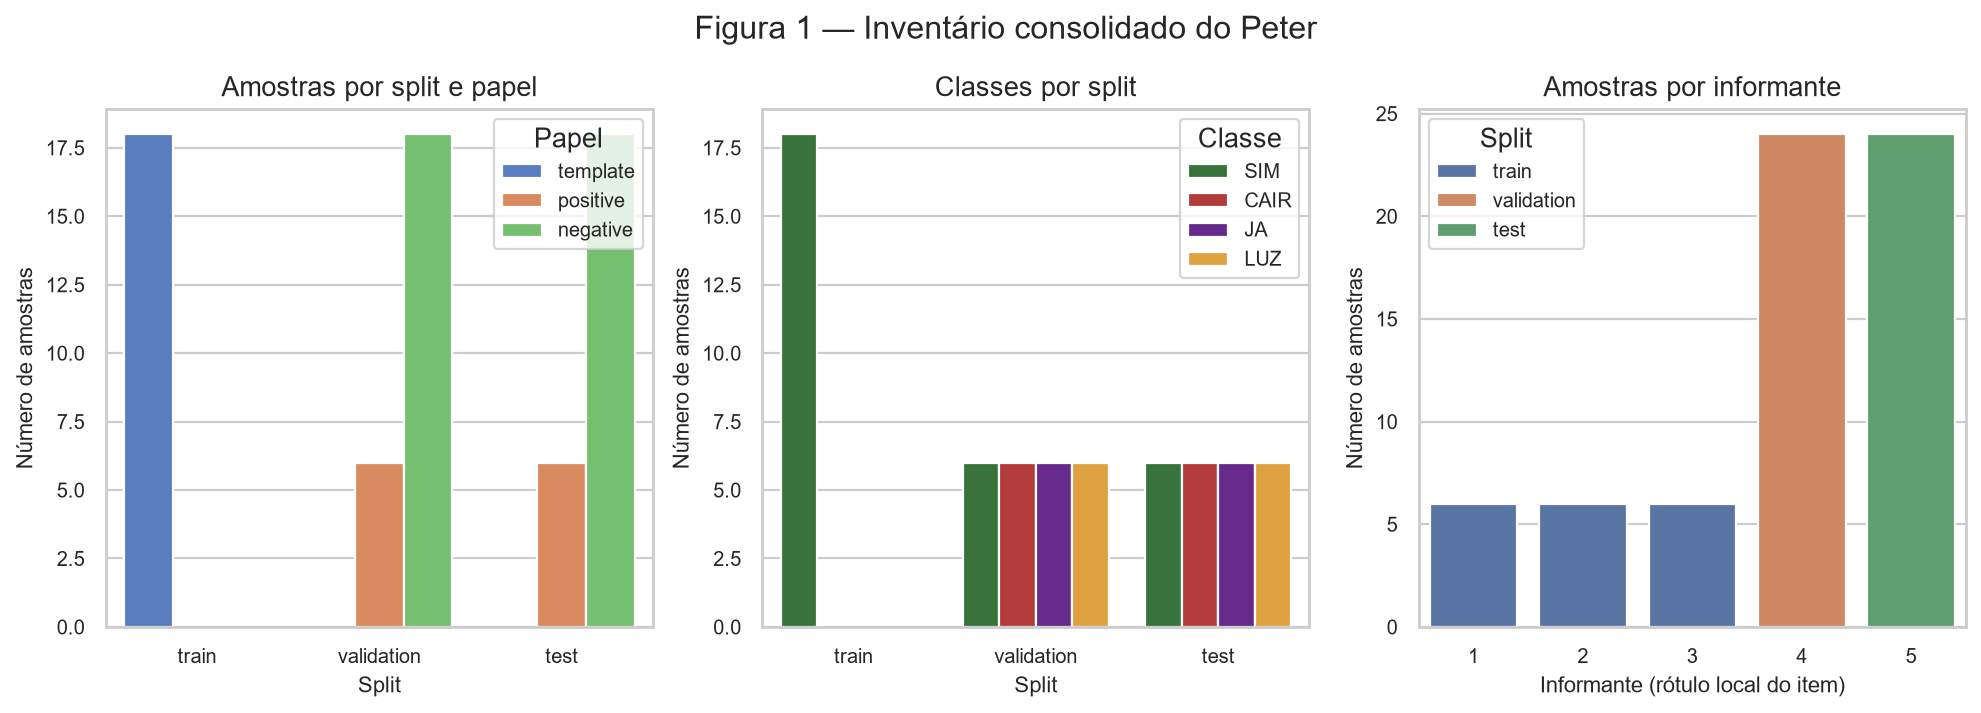

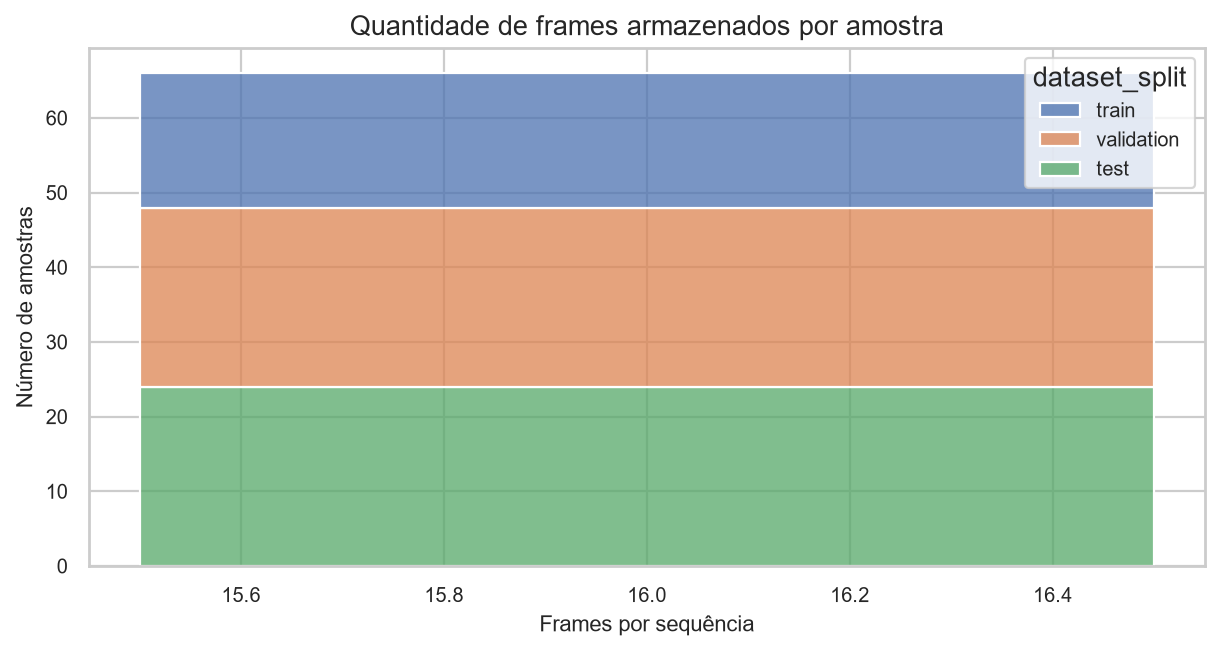

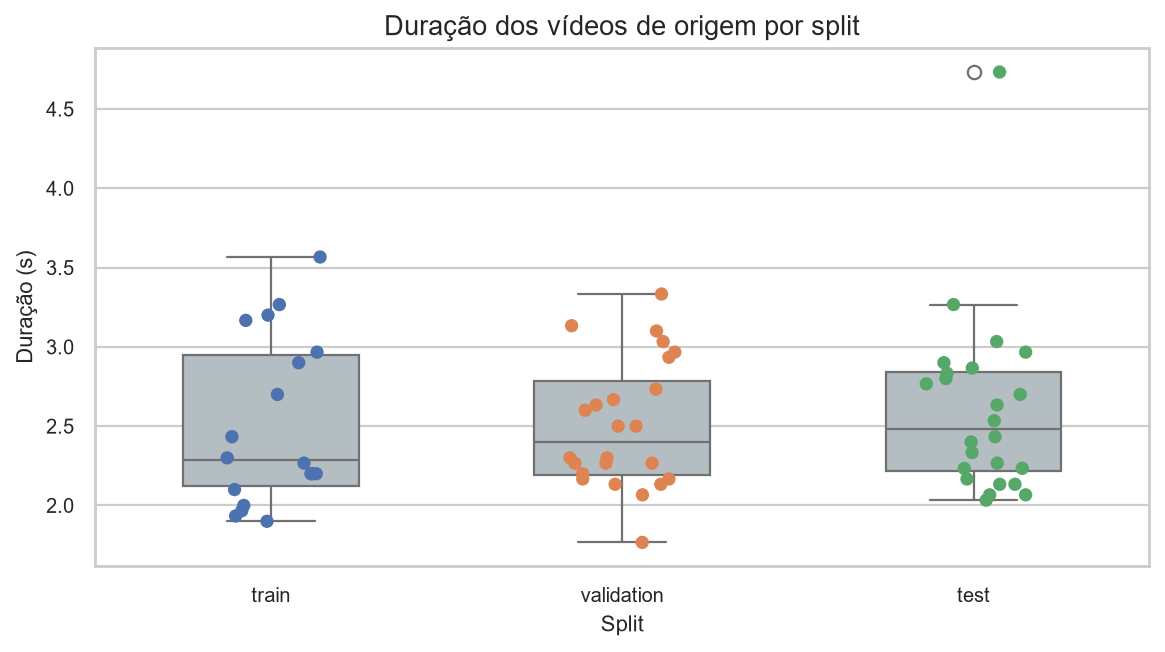

In [7]:
figure_paths = {}
figure_paths["contagens"] = visualization.plot_sample_counts(manifest_frame)
figure_paths["frames"] = visualization.plot_frame_counts(manifest_frame)
figure_paths["duracoes"] = visualization.plot_duration_distribution(manifest_frame)
show_paths(figure_paths)

A composição é desbalanceada por construção: o treino tem apenas a classe
`SIM` (18 templates), enquanto validação e teste têm 6 positivos e 18 negativos
cada. Isso significa que **especificidade é medida com três vezes mais amostras
que sensibilidade**; intervalos de confiança serão largos e serão reportados no
notebook 05.

As durações dos vídeos variam de ~1,8 s a ~4,7 s, mas todas as sequências
canônicas têm o mesmo *span* temporal (0,938 s), porque o extrator reamostra
para 16 frames. Duração de vídeo e duração da sequência não são a mesma coisa.

## 6. Cobertura das mãos e completude

A cobertura é a variável mais assimétrica do conjunto: os negativos de validação
têm mãos muito menos visíveis que os negativos de teste. Isso importa porque um
classificador poderia, em princípio, usar “mão visível” como atalho.

,figura
cobertura,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02...
mapa_visibilidade,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02...
completude,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02...
linha_tempo,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02...


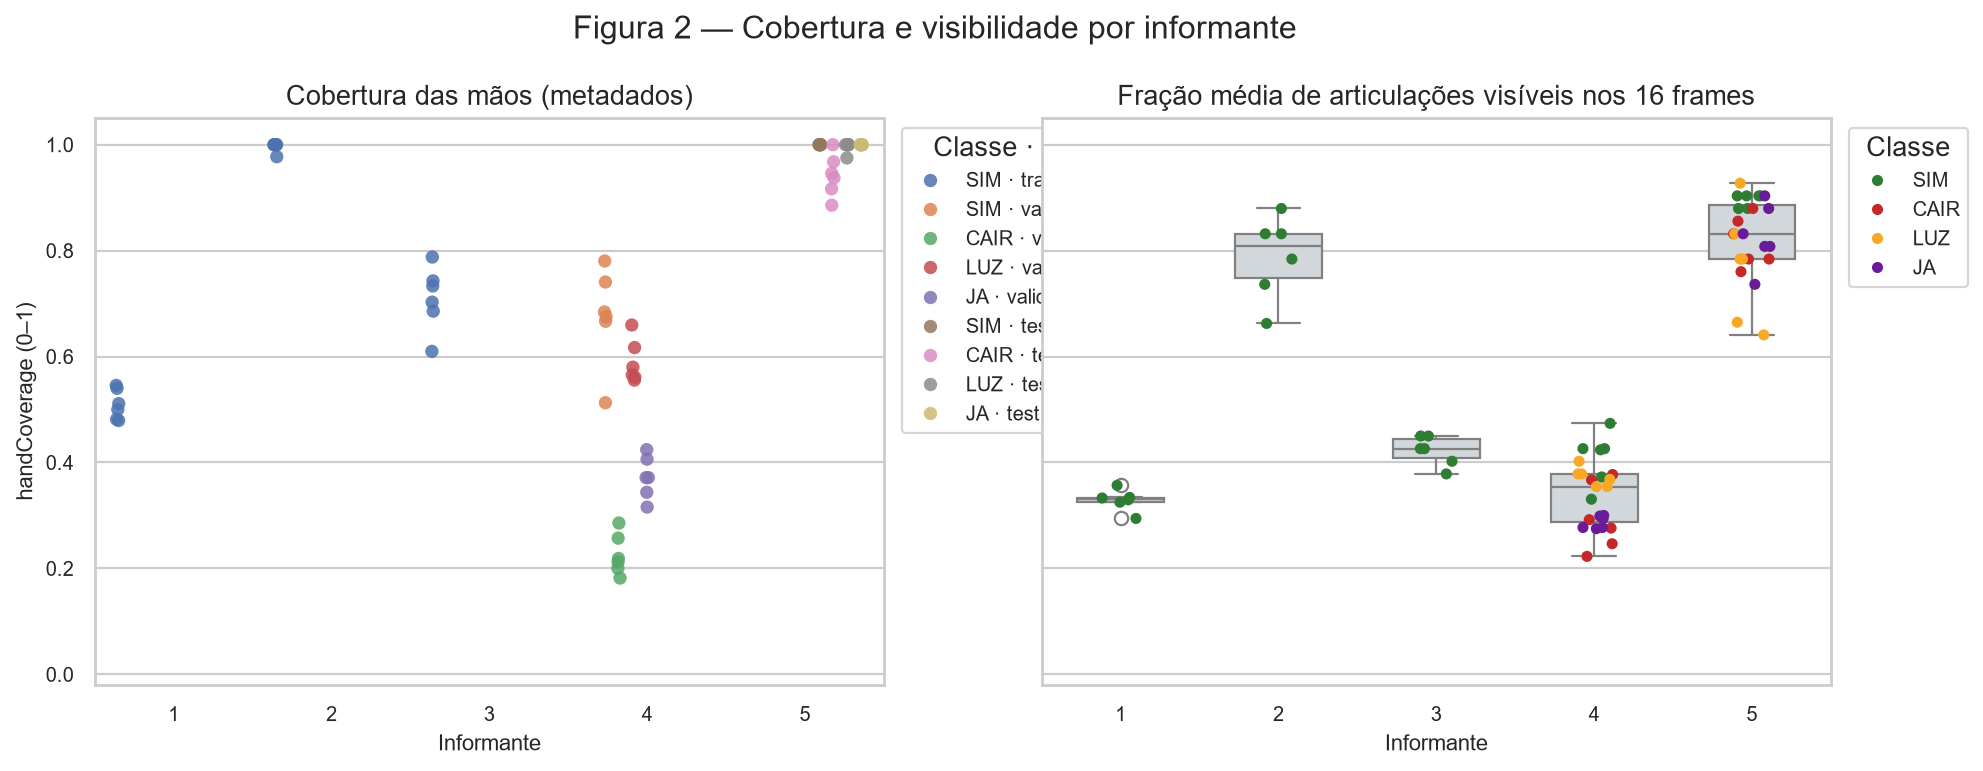

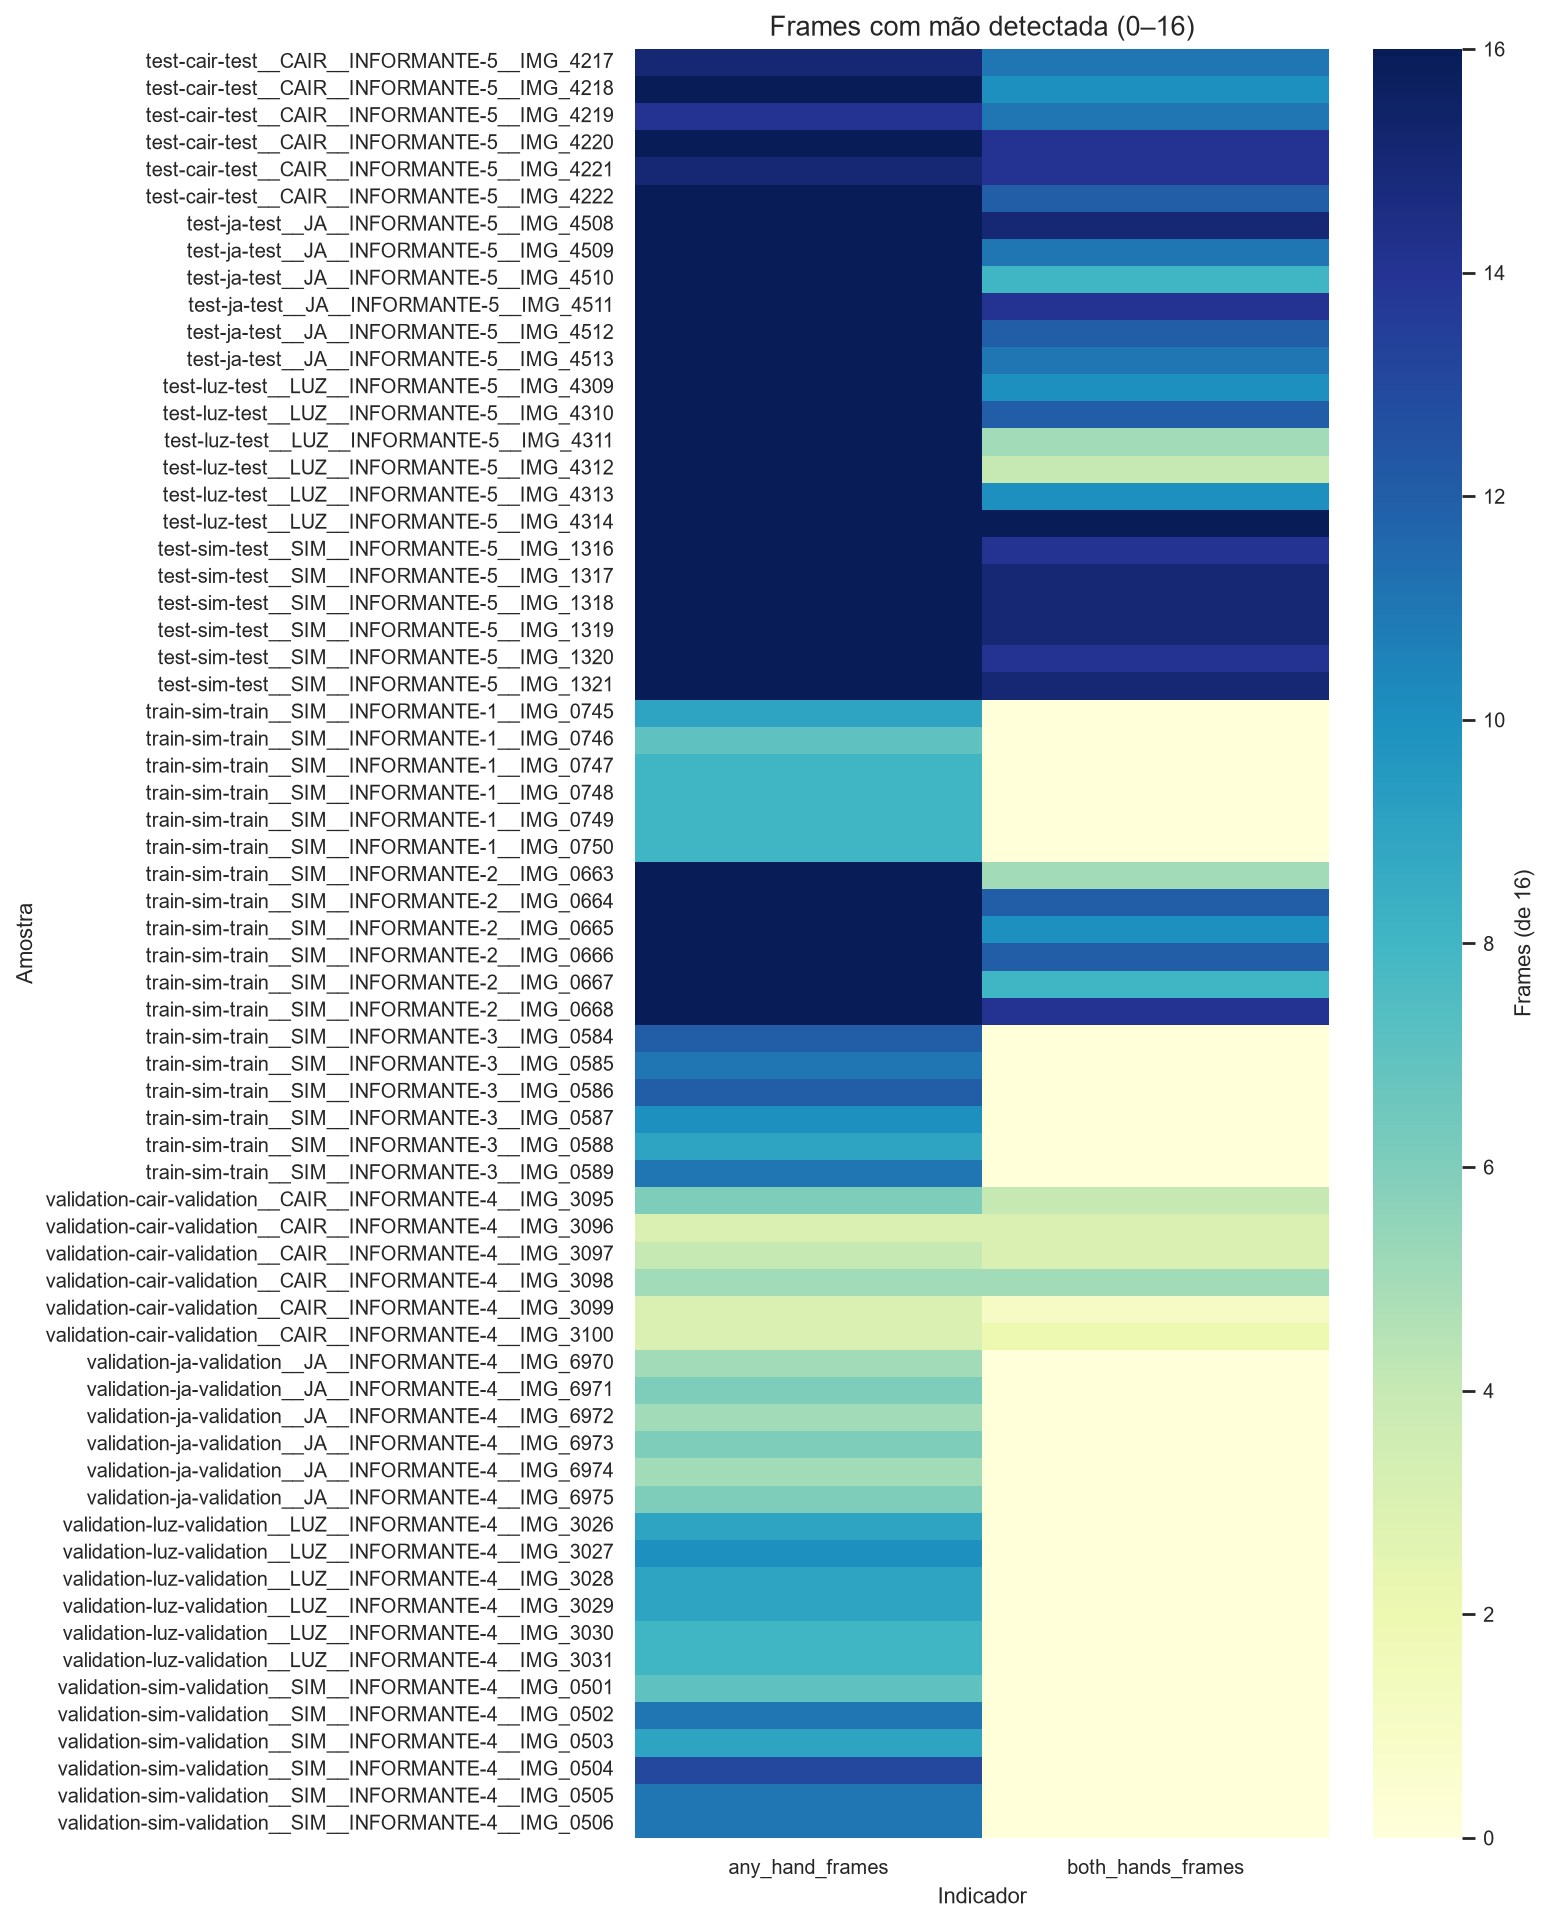

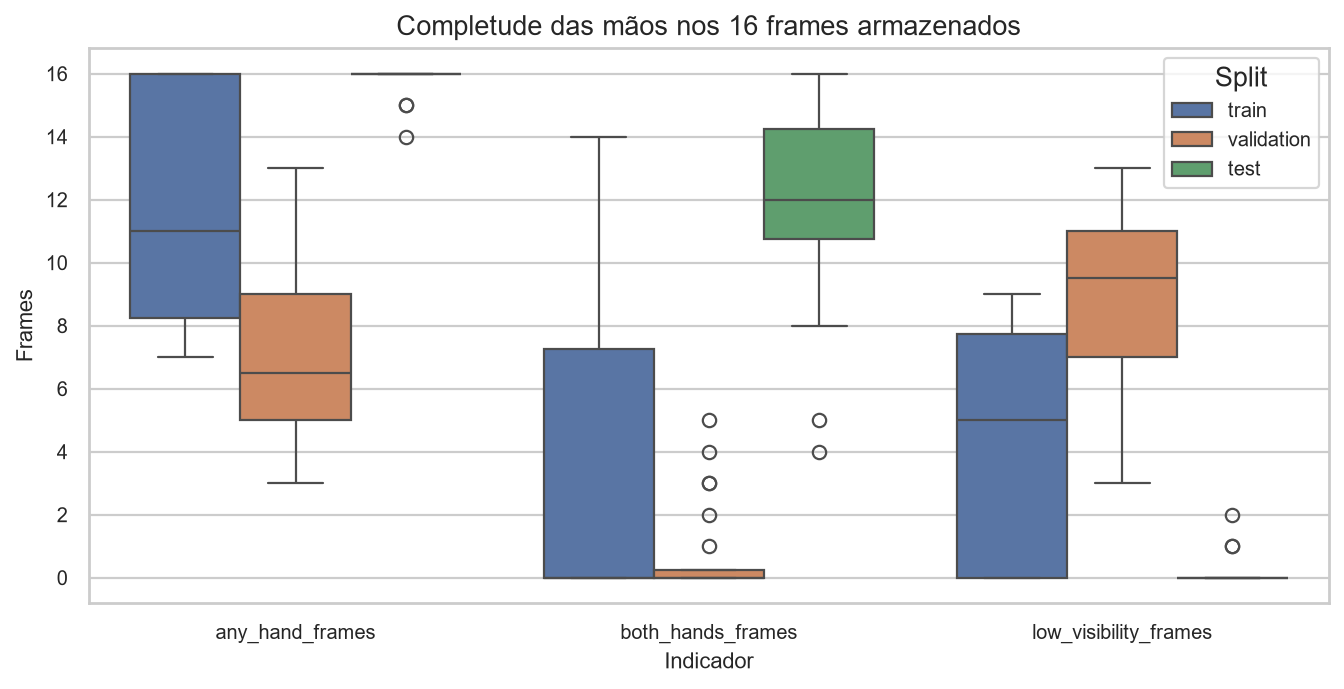

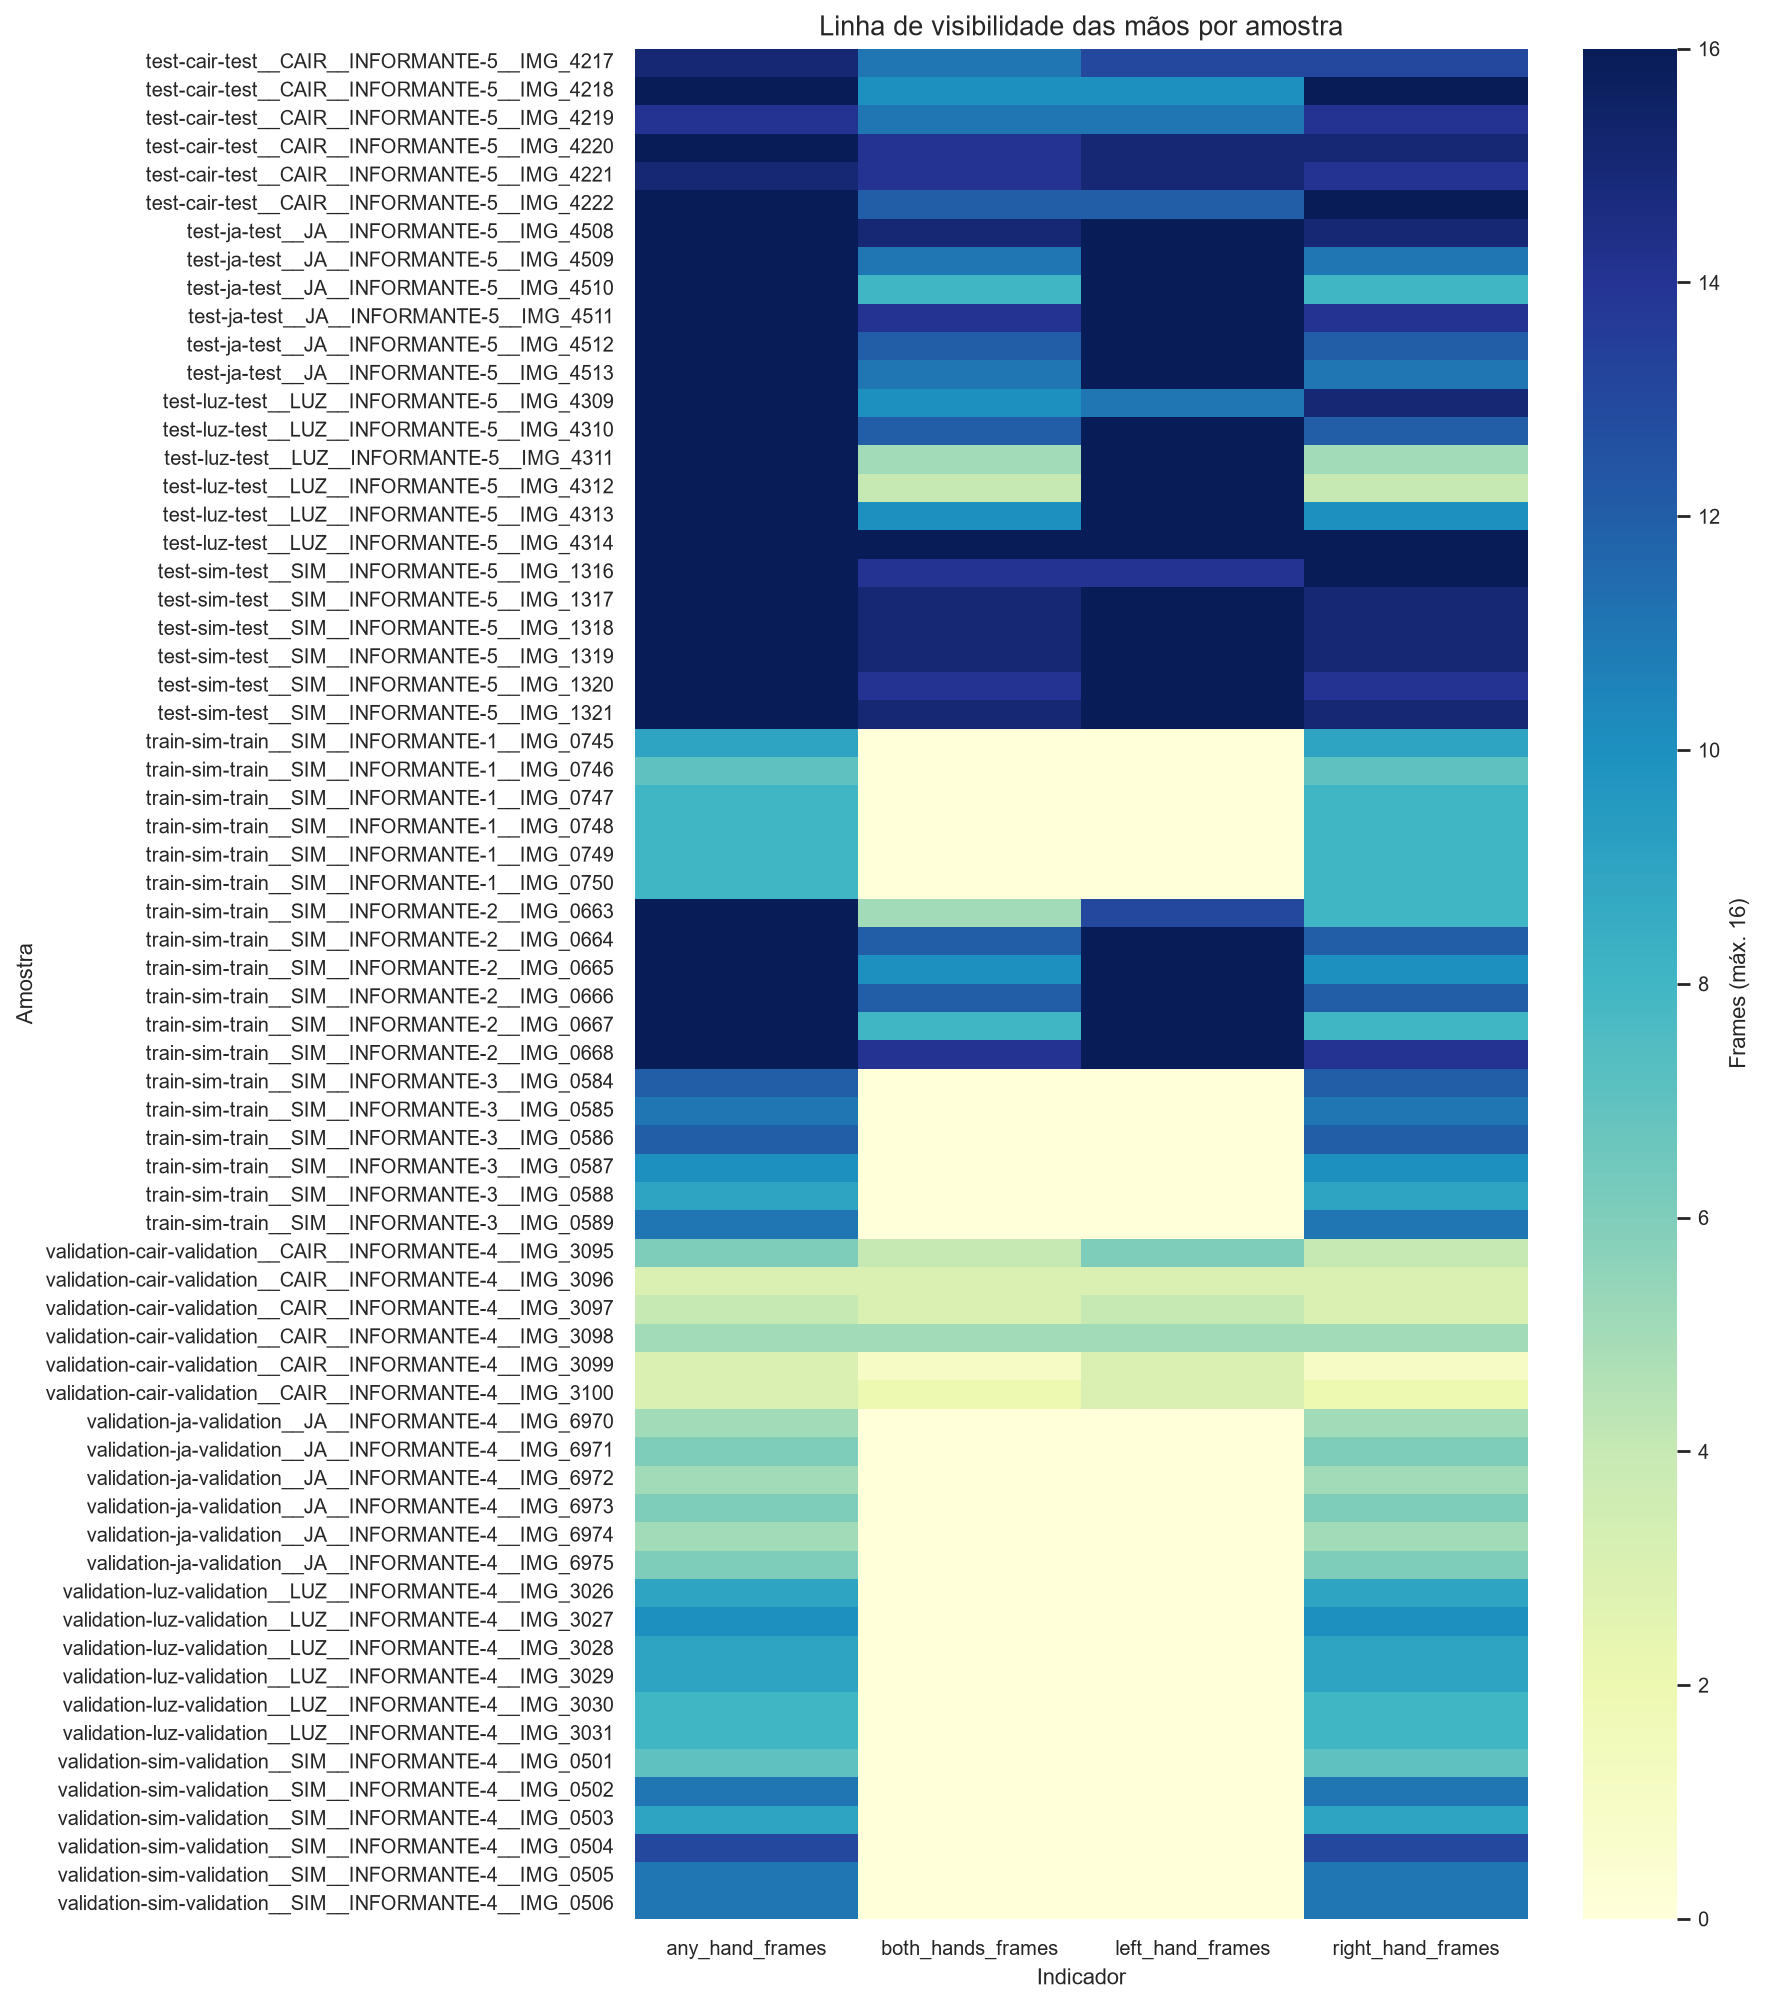

In [8]:
coverage_paths = {}
coverage_paths["cobertura"] = visualization.plot_coverage_by_informant(frame_quality)
coverage_paths["mapa_visibilidade"] = visualization.plot_visibility_heatmap(frame_quality)
coverage_paths["completude"] = visualization.plot_sequence_completeness(frame_quality)
coverage_paths["linha_tempo"] = visualization.plot_hand_visibility_timeline(frame_quality)
show_paths(coverage_paths)

In [9]:
coverage_table = (
    frame_quality.groupby(["dataset_split", "class_name"], dropna=False)
    .agg(
        n=("sample_id", "count"),
        hand_visibility_mean=("hand_coverage_metadata", "mean"),
        hand_visibility_min=("hand_coverage_metadata", "min"),
        hand_visibility_max=("hand_coverage_metadata", "max"),
        no_hand_frames_mean=("low_visibility_frames", "mean"),
        both_hands_frames_mean=("both_hands_frames", "mean"),
    )
    .reset_index()
)
display(coverage_table)

,dataset_split,class_name,n,hand_visibility_mean,hand_visibility_min,hand_visibility_max,no_hand_frames_mean,both_hands_frames_mean
0,test,CAIR,6,0.942261,0.885714,1.000000,0.666667,12.000000
1,test,JA,6,1.000000,1.000000,1.000000,0.000000,11.833333
2,test,LUZ,6,0.995833,0.975000,1.000000,0.000000,9.500000
3,test,SIM,6,1.000000,1.000000,1.000000,0.000000,14.666667
4,train,SIM,18,0.738717,0.479200,1.000000,4.388889,3.388889
5,validation,CAIR,6,0.225924,0.181818,0.285714,12.000000,3.000000
6,validation,JA,6,0.372148,0.315789,0.424242,10.500000,0.000000
7,validation,LUZ,6,0.589724,0.555556,0.659574,7.166667,0.000000
8,validation,SIM,6,0.676654,0.512821,0.780488,5.666667,0.000000


**Leitura.** A cobertura média das mãos cai de ~0,98 no teste para ~0,74 no
treino e ~0,47 na validação. Dentro da validação, os negativos `CAIR`, `LUZ` e
`JA` têm cobertura ~0,18–0,66, enquanto os positivos ficam em ~0,51–0,78. No
teste, todas as amostras estão em ~0,89–1,00, incluindo os seis `SIM`.

Ou seja: o teste é o split com **melhor** visibilidade e, ainda assim, é onde o
reconhecedor falha completamente. Cobertura baixa não é a explicação do colapso;
esse ponto será quantificado no notebook 04.

## 7. Relatório automático

O relatório em Markdown reúne os mesmos números em formato textual e fica
versionado em `outputs/reports/quality_report.md`.

In [10]:
report_text = quality.quality_report_markdown(
    manifest_frame, frame_quality, duplicates, low_visibility
)
report_path = config.output_path("report", "quality_report.md")
report_path.write_text(report_text, encoding="utf-8")
print("Relatório:", report_path)
display(Markdown(report_text))

Relatório: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\reports\quality_report.md


# Relatório de qualidade e cobertura — Peter EDA

> Gerado automaticamente por `peter_eda.quality`. Nenhuma amostra foi descartada ou imputada.

## Inventário analisado

- Amostras ativas no manifesto: **66**
- Templates de treino: **18**
- Amostras de validação: **24**
- Amostras de teste: **24**

## Integridade estrutural

- Sequências com comprimento diferente de 16 frames: **0**
- Sequências com valores NaN: **0**
- Sequências com valores infinitos: **0**
- Sequências com slots de articulação ausentes: **0**
- Sequências com timestamps não monotônicos: **0**

## Duplicatas

- Grupos de conteúdo duplicado: **0**
- Nenhuma sequência com conteúdo idêntico foi encontrada.

## Cobertura das mãos

| Recorte | n | handCoverage médio | frames sem mão (média) |
|---|---:|---:|---:|
| test / CAIR | 6 | 0.942 | 0.67 |
| test / JA | 6 | 1.000 | 0.00 |
| test / LUZ | 6 | 0.996 | 0.00 |
| test / SIM | 6 | 1.000 | 0.00 |
| train / SIM | 18 | 0.739 | 4.39 |
| validation / CAIR | 6 | 0.226 | 12.00 |
| validation / JA | 6 | 0.372 | 10.50 |
| validation / LUZ | 6 | 0.590 | 7.17 |
| validation / SIM | 6 | 0.677 | 5.67 |

## Frames com baixa visibilidade

- Frames sem nenhuma mão visível: **295**

## Limitações

- A cobertura oficial é calculada antes do downsampling para 16 frames; o valor recalculado nos frames armazenados é apenas uma aproximação.
- A ausência de vídeos no ZIP impede recalcular landmarks brutos, reavaliar a extração ou medir oclusão real fora dos 16 frames.
- Valores ausentes não foram imputados; qualquer comparação entre grupos carrega a incerteza de amostras muito pequenas (6 positivos por split).


## 8. Conclusões do notebook

1. O conjunto ativo é pequeno e balanceado apenas dentro de cada split:
   18 templates `SIM` no treino, 6 positivos + 18 negativos na validação e no
   teste.
2. A estrutura é íntegra: 16 frames, 55 articulações, sem `NaN`, sem duplicatas,
   timestamps monotônicos.
3. A cobertura das mãos é fortemente desigual entre splits e informantes, mas o
   teste tem a maior cobertura. Qualquer diagnóstico do colapso do teste precisa
   controlar por essa variável — o que será feito no notebook 04.
4. Os 24 templates legados `v4` existem, mas não são consumidos pelo runtime;
   tratá-los como treino inflaria artificialmente o conjunto.

## 9. Limitações deste notebook

- A cobertura recalculada nos 16 frames é aproximada; a cobertura oficial foi
  medida antes do downsampling e o denominador original não está no ZIP.
- Os rótulos de informante são **locais por item**, como o próprio fixture
  adverte; eles não garantem identidade física disjunta entre sinais diferentes.
  A análise de generalização entre informantes deve ser lida com essa ressalva.
- Os vídeos originais não estão no ZIP, então não é possível recalcular
  landmarks, reavaliar a extração ou medir oclusão fora dos 16 frames.
- O manifesto descreve os arquivos fornecidos; não é uma auditoria do processo
  de coleta.